# 🥚 Ellipse Detection From Scratch
### Canny (from scratch) → Direct Least-Squares + RANSAC ellipse fitting (from scratch) → OpenCV comparison

| Step | What happens | Interactive? |
|---|---|---|
| **0** | Imports + upload your own test images (a synthetic demo image is always available) | upload |
| **1** | Canny edge detection implemented in NumPy, with live **σ / low / high** tuning | ✅ sliders |
| **2** | Ellipse detection implemented in NumPy (**Halir–Flusser direct least squares + RANSAC**) with live tuning of **a_min, a_max, vote threshold, fit tolerance** | ✅ sliders |
| **3** | OpenCV reference (`findContours` + `fitEllipse`) and a side-by-side comparison of **accuracy, time and parameters** | table + plots |

**Why this approach?** The assignment allows either direct least squares or a Randomized Hough Transform. Direct least squares has a closed-form solution (no accumulator, no iteration, always returns an *ellipse*), so it is fast and easy to explain. Its weakness is that one bad pixel can ruin the fit and a single fit can only describe *one* ellipse — so Step 2 wraps it in a RANSAC loop that rejects outliers and can pull several ellipses out of one connected edge blob.

**Backend-ready by design:** all the algorithms live in a single NumPy-only file, `ellipse_core.py`, that the notebook writes to disk. Download it at the end and import it directly in your web backend (Flask / FastAPI / Django).

**Conventions used everywhere:** pixel coordinates, $x$ → right, $y$ → down. Orientation $\phi$ is the angle of the **major axis** from the $+x$ axis (so it looks *clockwise* on screen), range $[0°, 180°)$. Semi-axes: $a \ge b$.

> ▶️ Run the cells top to bottom (**Runtime → Run all**), then go back and play with the sliders.

---
## Step 0 — Setup & image upload

In [ ]:
import time, io, importlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import cv2                       # used ONLY for image I/O and for the Step-3 reference
import ipywidgets as widgets
from IPython.display import display

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:              # lets the notebook also run locally in Jupyter
    IN_COLAB = False

plt.rcParams.update({"figure.dpi": 100, "image.interpolation": "nearest"})
print("Running in Colab:", IN_COLAB)
# If sliders do not appear in Colab, run:
#   from google.colab import output; output.enable_custom_widget_manager()

Running in Colab: True


In [ ]:
# ── Upload test images (you can select several files at once) ──────────────────
MAX_DIM = 400      # longest image side after resizing. The from-scratch code is pure NumPy/Python,
                   # so keeping images ≲ 500 px keeps the sliders responsive.
                   # NOTE: all pixel parameters below (a_min, a_max, ...) refer to the RESIZED image.
IMAGES = {}        # name -> RGB uint8 array

def add_image(name, bgr_or_rgb, is_bgr=True):
    rgb = cv2.cvtColor(bgr_or_rgb, cv2.COLOR_BGR2RGB) if is_bgr else bgr_or_rgb
    h, w = rgb.shape[:2]
    if max(h, w) > MAX_DIM:
        s = MAX_DIM / max(h, w)
        rgb = cv2.resize(rgb, (int(round(w * s)), int(round(h * s))), interpolation=cv2.INTER_AREA)
    IMAGES[name] = rgb

def make_synthetic_image(h=320, w=420, seed=0, noise=10):
    '''Noisy test image: 4 ellipses of different size/orientation/contrast + a rectangle distractor.'''
    rng = np.random.default_rng(seed)
    img = np.tile(np.linspace(70, 110, w), (h, 1))                 # background gradient
    yy, xx = np.mgrid[0:h, 0:w]
    def ell(x0, y0, a, b, deg):
        t = np.radians(deg); dx, dy = xx - x0, yy - y0
        u = dx * np.cos(t) + dy * np.sin(t); v = -dx * np.sin(t) + dy * np.cos(t)
        return (u / a) ** 2 + (v / b) ** 2 <= 1
    img[ell(120, 120, 80, 50, 25)] = 205
    img[ell(300, 100, 55, 40, 100)] = 35
    img[ell(250, 240, 70, 35, 160)] = 190
    img[ell(90, 262, 30, 22, 0)] = 225
    img[285:315, 330:405] = 160                                    # NOT an ellipse -> should be rejected
    img = np.clip(img + rng.normal(0, noise, img.shape), 0, 255).astype(np.uint8)
    return np.stack([img, img, img], axis=-1)

IMAGES["synthetic_demo"] = make_synthetic_image()

if IN_COLAB:
    uploaded = files.upload()                                      # <- choose one or more images
    for fname, data in uploaded.items():
        arr = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
        if arr is None:
            print(f"⚠️ could not decode {fname}, skipped")
        else:
            add_image(fname, arr)
else:
    print("Not in Colab: using only the synthetic demo image (put files in IMAGES yourself).")

for k, v in IMAGES.items():
    print(f"{k:35s} {v.shape[1]}x{v.shape[0]} px")

Saving download.jpg to download (1).jpg
synthetic_demo                      420x320 px
download (1).jpg                    300x400 px


---
## Step 1 — Preprocessing & interactive Canny tuning

### What Canny does (in order)
1. **Gaussian blur** with standard deviation **σ** → suppresses noise.
2. **Sobel gradients** $G_x, G_y$ → magnitude $\sqrt{G_x^2+G_y^2}$ and direction.
3. **Non-maximum suppression** → thins every edge to ≈ 1 pixel by keeping only local maxima across the edge.
4. **Hysteresis thresholding** with **low** and **high**:
   - pixels $\ge$ *high* are **strong** edges (certain),
   - pixels between *low* and *high* are **weak** — kept *only if connected* to a strong pixel,
   - everything below *low* is discarded.

Everything is implemented in the next cell (NumPy only). Gradient magnitude is rescaled so the **strongest gradient in the image = 255**, so `low` / `high` (0–255) are *relative* strengths. This makes values easier to compare between images, but they are **not** the same numbers you would pass to `cv2.Canny`.

### 🎛️ How to choose the three parameters

**σ (Gaussian smoothing) — decide by image *noise*:**

| Image situation | Typical σ | Why |
|---|---|---|
| Clean, sharp, synthetic or studio photo | 0.8 – 1.4 | little noise to remove; keeps edges precise |
| Mild noise, JPEG artefacts | 1.4 – 2.2 | removes isolated speckles |
| Heavy noise / speckle / strong texture (ultrasound, fish scales, fruit peel) | 2.2 – 4 | texture must be blurred away or it becomes thousands of fake edges |

*Rule:* use the **smallest σ that makes the background speckle disappear**. Too large → outlines drift, blur together and small objects vanish (kernel radius is $3\sigma$ pixels).

**High threshold — decide by what the *noise gradient* looks like:** raise it until background speckle/texture stops producing isolated edge fragments; lower it if the object outline you care about starts breaking up.

**Low threshold — decide by *edge sharpness*:** a good start is `low ≈ 0.3 – 0.5 × high`.
- **Sharp, high-contrast edges** → the gap between the two can be large (more noise rejection, outlines stay intact).
- **Soft / blurry edges** (out-of-focus, medical boundaries) → lower `low` so weak parts of the outline stay connected to the strong parts.

**Visual checklist** (look at the right-hand panel):

| What you see | Fix |
|---|---|
| Object outlines are broken into pieces | lower `low` (and/or `high`); or reduce σ slightly |
| Lots of tiny speckles/lines in flat regions | raise `high` and/or σ |
| Outlines are thick/doubled | σ is too small *or* `low` too low (noise glued to edges) |
| Outlines exist but are wobbly / shifted | σ too large |
| Good: **thin, continuous, closed outlines around the objects, almost nothing else** | ✅ keep these values for Step 2 |

*The values you leave on the sliders are automatically used by Steps 2 and 3.*

In [ ]:
%%writefile ellipse_core.py
"""
ellipse_core.py  --  Ellipse detection written from scratch (NumPy only).

Pipeline:  gray image -> Canny (from scratch) -> connected edge components
           -> robust Direct-Least-Squares ellipse fitting (Halir-Flusser + RANSAC)

No OpenCV / scikit-image is used in this file, so it can be dropped straight
into a web-app backend (Flask / FastAPI / Django) that only has NumPy installed.

Conventions: pixel coordinates (x -> right, y -> down).  phi is the angle of the
major axis measured from the +x axis, in radians, range [0, pi).
"""
from dataclasses import dataclass, asdict
import numpy as np


# ----------------------------------------------------------------------------
# 1. Canny edge detector (from scratch)
# ----------------------------------------------------------------------------
def to_gray(img):
    """RGB / gray uint8 -> float64 gray in [0, 255] (ITU-R BT.601 luma)."""
    img = np.asarray(img, dtype=np.float64)
    if img.ndim == 2:
        return img
    return 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]


def gaussian_kernel_1d(sigma):
    radius = max(1, int(np.ceil(3.0 * sigma)))
    x = np.arange(-radius, radius + 1, dtype=np.float64)
    k = np.exp(-(x ** 2) / (2.0 * sigma ** 2))
    return k / k.sum()


def _corr1d(img, k, axis):
    """1-D correlation along `axis` with reflect padding (vectorised over taps)."""
    r = len(k) // 2
    r_eff = min(r, img.shape[axis] - 1)
    pad = [(0, 0), (0, 0)]
    pad[axis] = (r, r)
    p = np.pad(img, pad, mode="symmetric" if r_eff < r else "reflect")
    n = img.shape[axis]
    out = np.zeros(img.shape, dtype=np.float64)
    for i, w in enumerate(k):
        sl = [slice(None), slice(None)]
        sl[axis] = slice(i, i + n)
        out += w * p[tuple(sl)]
    return out


def gaussian_blur(gray, sigma):
    if sigma <= 0:
        return gray.astype(np.float64)
    k = gaussian_kernel_1d(sigma)
    return _corr1d(_corr1d(gray.astype(np.float64), k, 0), k, 1)


def sobel(gray):
    """Sobel gradients (gx, gy) using separable kernels."""
    smooth = np.array([1.0, 2.0, 1.0])
    diff = np.array([-1.0, 0.0, 1.0])
    gx = _corr1d(_corr1d(gray, smooth, 0), diff, 1)
    gy = _corr1d(_corr1d(gray, smooth, 1), diff, 0)
    return gx, gy


def _shift(a, dy, dx):
    """out[y, x] = a[y+dy, x+dx], zero outside the image."""
    h, w = a.shape
    p = np.pad(a, 1)
    return p[1 + dy:1 + dy + h, 1 + dx:1 + dx + w]


def non_max_suppression(mag, gx, gy):
    ang = np.degrees(np.arctan2(gy, gx)) % 180.0
    keep = np.zeros(mag.shape, dtype=bool)
    sectors = [
        ((ang < 22.5) | (ang >= 157.5), (0, 1)),     # gradient ~ horizontal
        ((ang >= 22.5) & (ang < 67.5), (1, 1)),      # diagonal  \
        ((ang >= 67.5) & (ang < 112.5), (1, 0)),     # vertical
        ((ang >= 112.5) & (ang < 157.5), (-1, 1)),   # diagonal  /
    ]
    for sel, (dy, dx) in sectors:
        n1 = _shift(mag, dy, dx)
        n2 = _shift(mag, -dy, -dx)
        keep |= sel & (mag >= n1) & (mag >= n2)
    return keep & (mag > 0)


def connected_components(mask):
    """8-connected components of a boolean mask -> list of (N, 2) float arrays [x, y]."""
    m = np.pad(mask.astype(np.uint8), 1)
    w2 = m.shape[1]
    flat = bytearray(m.ravel().tobytes())           # 1 = foreground, not yet visited
    offs = (-w2 - 1, -w2, -w2 + 1, -1, 1, w2 - 1, w2, w2 + 1)
    comps = []
    for start in np.flatnonzero(m.ravel()).tolist():
        if not flat[start]:
            continue
        flat[start] = 0
        stack, members = [start], []
        while stack:
            p = stack.pop()
            members.append(p)
            for o in offs:
                q = p + o
                if flat[q]:
                    flat[q] = 0
                    stack.append(q)
        ys, xs = np.divmod(np.asarray(members), w2)
        comps.append(np.column_stack([xs - 1, ys - 1]).astype(np.float64))
    return comps


def canny(gray, sigma=1.4, low=15.0, high=45.0):
    """
    Canny edge detector from scratch.  Returns a boolean edge map.

    low / high are on a 0-255 scale RELATIVE to the strongest gradient in the
    image (gradient magnitude is rescaled so its maximum equals 255).
    """
    low, high = float(min(low, high)), float(max(low, high))
    g = gaussian_blur(to_gray(gray), sigma)
    gx, gy = sobel(g)
    mag = np.hypot(gx, gy)
    if mag.max() <= 0:
        return np.zeros(mag.shape, dtype=bool)
    mag = mag * (255.0 / mag.max())
    nms = non_max_suppression(mag, gx, gy)
    strong = nms & (mag >= high)
    weak = nms & (mag >= low)
    # hysteresis: keep weak components that touch at least one strong pixel
    edges = np.zeros(mag.shape, dtype=bool)
    for pts in connected_components(weak):
        xs, ys = pts[:, 0].astype(int), pts[:, 1].astype(int)
        if strong[ys, xs].any():
            edges[ys, xs] = True
    return edges

Overwriting ellipse_core.py


In [ ]:
import ellipse_core as ec
importlib.reload(ec)

# Shared state: Steps 2 and 3 read whatever Step 1 produced last
state = dict(name=None, img=None, gray=None, edges=None, sigma=None, low=None, high=None,
             scratch=None, params=None)

style = {"description_width": "110px"}
lay = widgets.Layout(width="560px")
w_img   = widgets.Dropdown(options=list(IMAGES), description="Image", style=style, layout=lay)
w_sigma = widgets.FloatSlider(value=1.4, min=0.3, max=6.0, step=0.1, description="Sigma (σ)",
                              continuous_update=False, style=style, layout=lay)
w_low   = widgets.IntSlider(value=15, min=0, max=255, step=1, description="Lower threshold",
                            continuous_update=False, style=style, layout=lay)
w_high  = widgets.IntSlider(value=45, min=0, max=255, step=1, description="Upper threshold",
                            continuous_update=False, style=style, layout=lay)

def canny_view(name, sigma, low, high):
    img = IMAGES[name]
    gray = ec.to_gray(img)
    lo, hi = min(low, high), max(low, high)          # keep low <= high
    t0 = time.perf_counter()
    edges = ec.canny(gray, sigma, lo, hi)
    dt = (time.perf_counter() - t0) * 1000
    state.update(name=name, img=img, gray=gray, edges=edges, sigma=sigma, low=lo, high=hi,
                 scratch=None)

    fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
    ax[0].imshow(img);                    ax[0].set_title(f"Original — {name}")
    ax[1].imshow(edges, cmap="gray");     ax[1].set_title(f"Canny edges  (σ={sigma:.1f}, low={lo}, high={hi})")
    for a in ax: a.set_xlabel("x [px]"); a.set_ylabel("y [px]")
    plt.tight_layout(); plt.show()
    print(f"edge pixels: {edges.sum():,}  ({100*edges.mean():.2f}% of image)   |   time: {dt:.1f} ms"
          + ("   ⚠️ low > high was swapped" if low > high else ""))

out1 = widgets.interactive_output(canny_view, dict(name=w_img, sigma=w_sigma, low=w_low, high=w_high))
display(widgets.VBox([w_img, w_sigma, w_low, w_high]), out1)

Output()

---
## Step 2 — Ellipse detection from scratch

### 🧠 Concept first: how the algorithm works

**1. Ellipse as a conic.** Every ellipse satisfies
$$A x^2 + B xy + C y^2 + D x + E y + F = 0,\qquad B^2-4AC<0 .$$

**2. Direct least-squares fit (Fitzgibbon 1999; numerically stable version by Halir & Flusser 1998).** Given edge points $(x_i,y_i)$ we minimise the *algebraic distance* $\sum_i \big(\mathbf{a}^\top\mathbf{d}_i\big)^2$ with $\mathbf{d}_i=[x_i^2,\,x_iy_i,\,y_i^2,\,x_i,\,y_i,\,1]^\top$, subject to the constraint $4AC-B^2=1$. That constraint is what **forces the answer to be an ellipse** (a plain least-squares conic could return a hyperbola). The problem reduces to an eigen-problem; Halir–Flusser split $\mathbf{a}$ into the quadratic part $(A,B,C)$ and linear part $(D,E,F)$, which avoids a near-singular matrix. We also normalise the points (centre them, scale by RMS radius) before fitting.

**3. Conic → geometry.** The centre solves $\nabla f = 0$. With $Q=\begin{bmatrix}A&B/2\\B/2&C\end{bmatrix}$ and $f_c=f(\text{centre})$, the eigen-decomposition $Q=R\,\mathrm{diag}(\lambda_1,\lambda_2)R^\top$ gives semi-axes $\sqrt{-f_c/\lambda_i}$, and the eigenvector of the larger axis gives the orientation $\phi$.

**4. Making it robust (the part plain `fitEllipse` does not do).** Real edge maps contain noise, partial arcs and several touching ellipses, so:
   1. split the edge map into **8-connected components** (our own flood fill),
   2. for each component, run **RANSAC**: fit an ellipse to a few random *nearby* points, count **inliers** = edge pixels whose distance to the ellipse is `< fit_tolerance`,
   3. keep the best hypothesis and **refit on its inliers** (iterated),
   4. **validate**: semi-axes inside $[a_{min},a_{max}]$, not needle-like, enough inliers (`min_points`), and enough of the ellipse perimeter actually covered (`min_support`),
   5. **remove** its inliers and repeat (up to `max_ellipses` per component) → merged/overlapping ellipses get separated.

**5. Drawing.** Detected ellipses are rendered with the explicit parametric equation
$$x = x_0 + a\cos\theta\cos\phi - b\sin\theta\sin\phi,\qquad y = y_0 + a\cos\theta\sin\phi + b\sin\theta\cos\phi,\quad \theta\in[0,2\pi).$$

*(Randomized Hough would instead vote for $(x_0,y_0,a,b,\phi)$ using 3-point sampling and tangents; it needs an accumulator and is noticeably slower in pure Python, which is why we use the closed-form fit.)*

### 🎛️ The tunable parameters

| Parameter | Meaning | Too low → | Too high → |
|---|---|---|---|
| **a_min** (px) | smallest allowed **minor** semi-axis $b$ | tiny noise loops are reported as ellipses | small real objects are discarded |
| **a_max** (px) | largest allowed **major** semi-axis $a$ | huge false ellipses (image borders, merged blobs) are accepted; RANSAC pool also gets bigger → slower | large objects are rejected |
| **Vote threshold** `min_points` | minimum number of edge pixels that must support an ellipse (the "accumulator threshold") | fragments / clutter produce false positives | partially visible or small ellipses are missed |
| **Fit tolerance** (px) | max distance from the ellipse for an edge pixel to count as inlier | only near-perfect shapes survive; outlines of real objects break into several fits | wobbly non-elliptical shapes (and neighbours' edges) get absorbed |
| **Min. support** | fraction of the ellipse perimeter that must be covered by inliers (0–1) | ellipses "hallucinated" from a short arc | partially occluded objects rejected |
| **Max ellipses / component** | how many ellipses may be extracted from one connected edge blob | overlapping ellipses stay merged | extra spurious detections from leftovers |
| **RANSAC iterations** | random hypotheses per search | may miss ellipses in cluttered blobs | slower |

**How to measure `a_min` / `a_max`:** the plots keep their pixel axes on — read the object's half-width / half-height from the tick marks (remember: pixels of the *resized* image, longest side = `MAX_DIM`). Start with `a_min ≈ 0.6 ×` smallest object's minor semi-axis and `a_max ≈ 1.3 ×` largest object's major semi-axis.

**Suggested starting points by image type** (tune from here — these are heuristics, not rules):

| Image type | Canny σ | Fit tolerance | Min. support | Vote threshold | Notes |
|---|---|---|---|---|---|
| **Clean / synthetic / studio** | 1.0 – 1.4 | 1.5 – 2 | 0.7 – 0.9 | 30 – 60 | edges are exact, so be strict to reject clutter |
| **Medical scans** (ultrasound, MRI/CT slices, cell/organ cross-sections) | 2 – 3.5 | 2.5 – 4 | 0.35 – 0.5 | 60 – 150 | speckle noise + fuzzy, often incomplete boundaries → heavy smoothing, tolerant fit, accept partial arcs; set `a_min`/`a_max` from the *anatomical* size range you expect |
| **Fish** (side views, elongated bodies) | 2 – 3 | 3 – 5 | 0.4 – 0.6 | 60 – 150 | scale texture and fins make the outline irregular → large σ & tolerance; body is elongated, so `a` ≳ 2–3 × `b` (raise `max_aspect` in `EllipseParams` if needed) |
| **Fruits / eggs** (oranges, lemons, eggs, plums) | 1.2 – 2 (higher for textured peel) | 1.5 – 2.5 | 0.6 – 0.8 | 40 – 100 | smooth, high-contrast, nearly circular (⇒ the angle φ is *meaningless* when $a\approx b$); plain background makes strict settings work well |
| **Many touching objects** | as above | as above | 0.4 – 0.6 | as above | increase *Max ellipses / component* and *RANSAC iterations* |

**Typical failure → fix:** nothing detected → lower *Min. support* and *Vote threshold*, raise *Fit tolerance*, check `a_min`/`a_max`. Too many detections → do the opposite, or go back to Step 1 and clean the edge map (the single biggest quality lever).

In [ ]:
%%writefile -a ellipse_core.py

# ----------------------------------------------------------------------------
# 2. Direct least-squares ellipse fitting (Halir & Flusser, numerically stable)
# ----------------------------------------------------------------------------
def _conic_to_geometric(A, B, C, D, E, F, mx, my, s):
    """Conic coefficients (in normalised coords) -> (x0, y0, a, b, phi) in pixels."""
    det = A * C - B * B / 4.0
    if not np.isfinite(det) or abs(det) < 1e-14:
        return None
    Q = np.array([[A, B / 2.0], [B / 2.0, C]])
    try:
        c = np.linalg.solve(2.0 * Q, np.array([-D, -E]))
    except np.linalg.LinAlgError:
        return None
    Fc = F + 0.5 * (D * c[0] + E * c[1])
    evals, evecs = np.linalg.eigh(Q)
    if np.any(np.abs(evals) < 1e-14):
        return None
    r = -Fc / evals
    if np.any(r <= 0):
        return None
    axes = np.sqrt(r)
    i = int(np.argmax(axes))
    a, b = axes[i], axes[1 - i]
    v = evecs[:, i]
    phi = float(np.arctan2(v[1], v[0]) % np.pi)
    return (c[0] * s + mx, c[1] * s + my, a * s, b * s, phi)


def fit_ellipse(pts):
    """
    Direct least-squares ellipse fit (Fitzgibbon 1999, Halir-Flusser 1998 variant).
    Minimises the algebraic distance subject to 4AC - B^2 = 1, which GUARANTEES
    that the result is an ellipse.  pts: (N>=5, 2) array of [x, y].
    Returns (x0, y0, a, b, phi) or None.
    """
    pts = np.asarray(pts, dtype=np.float64)
    if len(pts) < 5:
        return None
    x, y = pts[:, 0], pts[:, 1]
    mx, my = x.mean(), y.mean()
    s = np.sqrt(np.mean((x - mx) ** 2 + (y - my) ** 2))
    if s < 1e-9:
        return None
    xn, yn = (x - mx) / s, (y - my) / s
    D1 = np.column_stack([xn * xn, xn * yn, yn * yn])      # quadratic part
    D2 = np.column_stack([xn, yn, np.ones_like(xn)])       # linear part
    S1, S2, S3 = D1.T @ D1, D1.T @ D2, D2.T @ D2
    try:
        T = -np.linalg.solve(S3, S2.T)
        M = S1 + S2 @ T
        M = np.vstack([M[2] / 2.0, -M[1], M[0] / 2.0])      # C1^-1 * M
        _, vec = np.linalg.eig(M)
    except np.linalg.LinAlgError:
        return None
    vec = np.real(vec)
    cond = 4.0 * vec[0] * vec[2] - vec[1] ** 2
    ok = np.flatnonzero(cond > 0)
    if len(ok) == 0:
        return None
    a1 = vec[:, ok[np.argmax(cond[ok])]]
    a2 = T @ a1
    A, B, C, D, E, F = np.concatenate([a1, a2])
    return _conic_to_geometric(A, B, C, D, E, F, mx, my, s)


def ellipse_distance(pts, e):
    """First-order (Sampson) approximation of the geometric distance in pixels."""
    x0, y0, a, b, phi = e
    c, s = np.cos(phi), np.sin(phi)
    dx, dy = pts[:, 0] - x0, pts[:, 1] - y0
    u, v = dx * c + dy * s, -dx * s + dy * c
    f = (u / a) ** 2 + (v / b) ** 2 - 1.0
    g = np.sqrt((2 * u / a ** 2) ** 2 + (2 * v / b ** 2) ** 2) + 1e-12
    return np.abs(f) / g


def ellipse_perimeter(a, b):
    """Ramanujan's approximation."""
    return np.pi * (3 * (a + b) - np.sqrt((3 * a + b) * (a + 3 * b)))


# ----------------------------------------------------------------------------
# 3. Robust multi-ellipse detection on an edge map
# ----------------------------------------------------------------------------
@dataclass
class EllipseParams:
    a_min: float = 10.0          # smallest allowed semi-axis (applies to the MINOR axis b)
    a_max: float = 150.0         # largest allowed semi-axis  (applies to the MAJOR axis a)
    min_points: int = 40         # min. edge pixels supporting an ellipse ("vote threshold")
    fit_tol: float = 2.0         # max. distance (px) for an edge pixel to count as an inlier
    min_support: float = 0.5     # min. fraction of the ellipse perimeter covered by inliers
    max_ellipses: int = 3        # max. ellipses extracted from ONE connected edge component
    ransac_iters: int = 300      # random hypotheses per search
    sample_size: int = 6         # points per hypothesis (>= 5)
    max_aspect: float = 10.0     # reject needle-like ellipses (a / b)
    seed: int = 0                # makes results reproducible


def _valid(e, p):
    if e is None or not np.all(np.isfinite(e)):
        return False
    _, _, a, b, _ = e
    return b >= p.a_min and a <= p.a_max and (a / b) <= p.max_aspect


def _refine(pts, e, p, iters=3):
    """Iteratively refit on the inliers of the current ellipse."""
    for _ in range(iters):
        inl = ellipse_distance(pts, e) < p.fit_tol
        if inl.sum() < 5:
            break
        e2 = fit_ellipse(pts[inl])
        if not _valid(e2, p):
            break
        e = e2
    return e, ellipse_distance(pts, e) < p.fit_tol


def _best_ellipse(pts, p, rng):
    n = len(pts)
    best, best_cnt = None, 0
    cands = [fit_ellipse(pts)]                       # hypothesis 0: fit everything
    for k in range(p.ransac_iters + 1):
        if k == 0:
            e = cands[0]
        else:
            seed = pts[rng.integers(n)]
            d = np.hypot(pts[:, 0] - seed[0], pts[:, 1] - seed[1])
            pool = np.flatnonzero(d <= 2.0 * p.a_max)
            if len(pool) < p.sample_size:
                continue
            e = fit_ellipse(pts[rng.choice(pool, p.sample_size, replace=False)])
        if not _valid(e, p):
            continue
        cnt = int((ellipse_distance(pts, e) < p.fit_tol).sum())
        if cnt > best_cnt:
            best, best_cnt = e, cnt
            if cnt >= 0.95 * n:                      # (almost) all points explained
                break
    if best is None:
        return None, None
    best, inl = _refine(pts, best, p)
    return best, inl


def detect_ellipses(edges, params=None):
    """
    Detect ellipses in a boolean edge map.
    Returns a list of dicts: x0, y0, a, b, phi (rad), phi_deg, n_inliers, support, rms
    sorted by support (best first).
    """
    p = params or EllipseParams()
    rng = np.random.default_rng(p.seed)
    results = []
    for comp in connected_components(edges):
        remaining = comp
        for _ in range(p.max_ellipses):
            if len(remaining) < max(p.min_points, 5):
                break
            e, inl = _best_ellipse(remaining, p, rng)
            if e is None:
                break
            n_in = int(inl.sum())
            support = n_in / ellipse_perimeter(e[2], e[3])
            if n_in < p.min_points or support < p.min_support:
                break
            rms = float(np.sqrt(np.mean(ellipse_distance(remaining[inl], e) ** 2)))
            results.append(dict(x0=float(e[0]), y0=float(e[1]), a=float(e[2]), b=float(e[3]),
                                phi=float(e[4]), phi_deg=float(np.degrees(e[4])),
                                n_inliers=n_in, support=float(min(support, 1.0)), rms=rms))
            # remove explained points (slightly looser tol to clear leftovers)
            remaining = remaining[ellipse_distance(remaining, e) >= 1.5 * p.fit_tol]
    results.sort(key=lambda r: -r["support"])
    return results


def detect_from_image(img, sigma=1.4, low=15.0, high=45.0, params=None):
    """Convenience wrapper for a backend: image array -> (edge map, ellipse list)."""
    edges = canny(img, sigma, low, high)
    return edges, detect_ellipses(edges, params)


# ----------------------------------------------------------------------------
# 4. Drawing with the explicit parametric equation
# ----------------------------------------------------------------------------
def ellipse_points(x0, y0, a, b, phi, n=360):
    """x = x0 + a cos t cos(phi) - b sin t sin(phi);  y = y0 + a cos t sin(phi) + b sin t cos(phi)"""
    t = np.linspace(0.0, 2.0 * np.pi, n, endpoint=False)
    x = x0 + a * np.cos(t) * np.cos(phi) - b * np.sin(t) * np.sin(phi)
    y = y0 + a * np.cos(t) * np.sin(phi) + b * np.sin(t) * np.cos(phi)
    return x, y


def draw_ellipse(img, e, color=(0, 255, 0), thickness=2):
    """Rasterise the parametric ellipse into `img` (H, W, 3) in place. e = dict or tuple."""
    if isinstance(e, dict):
        e = (e["x0"], e["y0"], e["a"], e["b"], e["phi"])
    x0, y0, a, b, phi = e
    h, w = img.shape[:2]
    n = max(180, int(4 * ellipse_perimeter(a, b)))
    x, y = ellipse_points(x0, y0, a, b, phi, n)
    xi, yi = np.round(x).astype(int), np.round(y).astype(int)
    r = thickness // 2
    for dy in range(-r, r + 1):
        for dx in range(-r, r + 1):
            yy, xx = yi + dy, xi + dx
            ok = (yy >= 0) & (yy < h) & (xx >= 0) & (xx < w)
            img[yy[ok], xx[ok]] = color
    return img


def ellipse_mask(shape, e):
    """Filled boolean mask of the ellipse (implicit equation) -- used for IoU."""
    if isinstance(e, dict):
        e = (e["x0"], e["y0"], e["a"], e["b"], e["phi"])
    x0, y0, a, b, phi = e
    yy, xx = np.mgrid[0:shape[0], 0:shape[1]]
    dx, dy = xx - x0, yy - y0
    c, s = np.cos(phi), np.sin(phi)
    u, v = dx * c + dy * s, -dx * s + dy * c
    return (u / a) ** 2 + (v / b) ** 2 <= 1.0

Appending to ellipse_core.py


In [ ]:
importlib.reload(ec)       # load the full ellipse_core.py (Canny + ellipse fitting)

COLORS = [(0, 255, 0), (255, 0, 0), (0, 128, 255), (255, 165, 0), (255, 0, 255),
          (0, 255, 255), (255, 255, 0), (160, 80, 255)]

s2 = dict(style=style, layout=lay, continuous_update=False)
w_amin = widgets.IntSlider(value=10, min=2, max=200, description="a_min (px)", **s2)
w_amax = widgets.IntSlider(value=150, min=10, max=400, description="a_max (px)", **s2)
w_pts  = widgets.IntSlider(value=40, min=10, max=500, description="Vote threshold", **s2)
w_tol  = widgets.FloatSlider(value=2.0, min=0.5, max=8.0, step=0.1, description="Fit tolerance", **s2)
w_sup  = widgets.FloatSlider(value=0.5, min=0.1, max=1.0, step=0.05, description="Min. support", **s2)
w_maxe = widgets.IntSlider(value=3, min=1, max=8, description="Max ell./component", **s2)
w_iter = widgets.IntSlider(value=300, min=50, max=1500, step=50, description="RANSAC iters", **s2)

def scratch_view(a_min, a_max, min_points, fit_tol, min_support, max_ellipses, ransac_iters):
    if state["edges"] is None:
        print("Run the Step 1 cell first."); return
    if a_min >= a_max:
        print("⚠️ a_min must be smaller than a_max"); return
    p = ec.EllipseParams(a_min=a_min, a_max=a_max, min_points=min_points, fit_tol=fit_tol,
                         min_support=min_support, max_ellipses=max_ellipses,
                         ransac_iters=ransac_iters)
    t0 = time.perf_counter()
    ells = ec.detect_ellipses(state["edges"], p)
    dt = (time.perf_counter() - t0) * 1000
    state.update(scratch=ells, params=p, scratch_ms=dt)

    overlay = state["img"].copy()
    for i, e in enumerate(ells):                      # parametric drawing from scratch
        ec.draw_ellipse(overlay, e, COLORS[i % len(COLORS)], thickness=2)

    fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
    ax[0].imshow(state["img"]);              ax[0].set_title("Original")
    ax[1].imshow(state["edges"], cmap="gray"); ax[1].set_title(f"Edge map from Step 1 (σ={state['sigma']:.1f}, "
                                                              f"{state['low']}/{state['high']})")
    ax[2].imshow(overlay);                   ax[2].set_title(f"From-scratch detection: {len(ells)} ellipse(s)")
    for i, e in enumerate(ells):
        c = np.array(COLORS[i % len(COLORS)]) / 255
        ax[2].plot(e["x0"], e["y0"], "+", color=c, ms=10, mew=2)
        ax[2].text(e["x0"] + 4, e["y0"] - 4, str(i), color=c, fontsize=11, weight="bold",
                   bbox=dict(facecolor="black", alpha=0.5, pad=1, lw=0))
    for a in ax: a.set_xlabel("x [px]"); a.set_ylabel("y [px]")
    plt.tight_layout(); plt.show()

    print(f"detection time: {dt:.1f} ms")
    if ells:
        df = pd.DataFrame(ells)[["x0", "y0", "a", "b", "phi_deg", "n_inliers", "support", "rms"]]
        df.columns = ["center x0", "center y0", "semi-major a", "semi-minor b", "angle φ [deg]",
                      "inliers", "support", "rms err [px]"]
        display(df.round(2))
    else:
        print("No ellipse found — see the tuning guide above.")

out2 = widgets.interactive_output(scratch_view, dict(
    a_min=w_amin, a_max=w_amax, min_points=w_pts, fit_tol=w_tol, min_support=w_sup,
    max_ellipses=w_maxe, ransac_iters=w_iter))
display(widgets.VBox([widgets.HTML("<b>Ellipse parameters</b> (re-runs when you release a slider; "
                                   "edge map comes from the Step 1 sliders)"),
                      w_amin, w_amax, w_pts, w_tol, w_sup, w_maxe, w_iter]), out2)

Output()

---
## Step 3 — OpenCV built-in reference & comparison

**Reference method:** `cv2.findContours` → `cv2.fitEllipse` on every contour, filtered with the *same* `a_min`, `a_max` and vote threshold as our method.

**Fairness rules**
- Both methods receive the **same edge map** (from Step 1) and the **same parameters** (from Step 2's sliders).
- Both results are **drawn with our own parametric drawing function**, so the visual comparison is not affected by different rendering code.
- `cv2.fitEllipse` returns *full* axis lengths and its own angle convention; we convert to semi-axes $a\ge b$ and $\phi\in[0°,180°)$ so numbers are directly comparable.

**Metrics logged**
1. **Visual accuracy** — overlay of both results, per-ellipse **IoU** (overlap of the filled ellipses), and **edge coverage** (share of all edge pixels lying within `fit_tolerance` of *some* detected ellipse).
2. **Execution time** — mean ± std over several runs using `time.perf_counter()` (detection stage only, edge map already computed).
3. **Detected parameters** — centre, semi-axes, angle, with differences for matched pairs.

In [ ]:
def opencv_detect(edges, p):
    '''Reference: findContours + fitEllipse, same size filters as the from-scratch method.'''
    contours, _ = cv2.findContours(edges.astype(np.uint8) * 255, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
    out = []
    for c in contours:
        if len(c) < max(5, p.min_points):
            continue
        (cx, cy), (w, h), ang = cv2.fitEllipse(c)
        a, b, phi = (w / 2, h / 2, ang) if w >= h else (h / 2, w / 2, ang + 90.0)   # major axis first
        if b < p.a_min or a > p.a_max:
            continue
        # a closed 1-px edge loop gives TWO contours (outer + inner side) -> drop near-duplicates
        if any(np.hypot(cx - o["x0"], cy - o["y0"]) < 3 and abs(a - o["a"]) < 3 and abs(b - o["b"]) < 3 for o in out):
            continue
        out.append(dict(x0=cx, y0=cy, a=a, b=b, phi=np.radians(phi % 180), phi_deg=phi % 180))
    return out

print("OpenCV", cv2.__version__, "reference ready.")

OpenCV 5.0.0 reference ready.


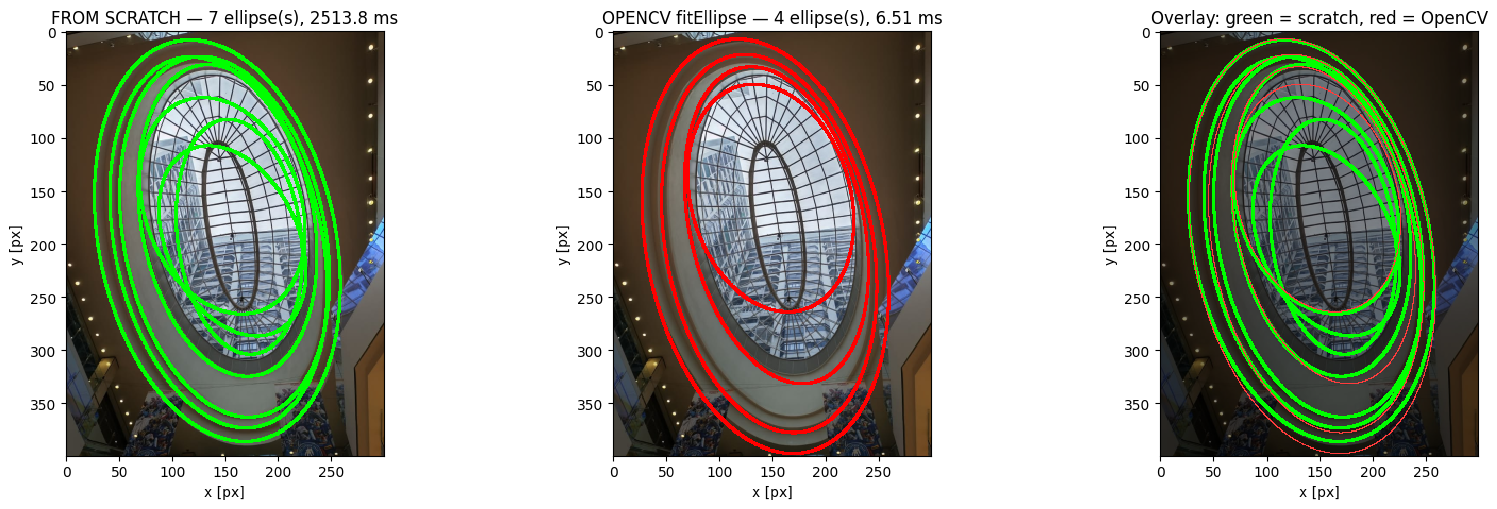

Matched ellipses (nearest centre)  —  NB: φ is meaningless for near-circular ellipses (a≈b)


,"scratch (x0,y0)",scratch a/b,scratch φ°,"OpenCV (x0,y0)",OpenCV a/b,OpenCV φ°,Δcenter px,Δa,Δb,Δφ°,IoU
#,,,,,,,,,,,
0,"(141.8, 196.9)",191.6 / 111.3,78.3,"(146.3, 199.6)",180.0 / 97.4,79.5,5.23,11.57,13.94,1.2,0.822
1,"(148.6, 193.2)",171.8 / 94.7,79.0,"(142.8, 202.1)",197.6 / 111.7,78.7,10.69,-25.78,-16.98,0.2,0.737
2,"(151.4, 177.9)",148.5 / 81.1,79.7,"(153.4, 182.3)",151.8 / 81.6,77.0,4.85,-3.34,-0.51,2.7,0.948
3,"(146.7, 164.0)",105.1 / 73.1,69.6,"(147.8, 156.8)",109.4 / 75.0,73.7,7.29,-4.25,-1.82,4.1,0.908
4,"(162.4, 193.2)",111.2 / 58.0,82.5,—,—,NaN,NaN,NaN,NaN,NaN,NaN
5,"(156.1, 197.0)",94.9 / 61.8,64.2,—,—,NaN,NaN,NaN,NaN,NaN,NaN
6,"(142.9, 198.5)",177.3 / 97.4,77.9,—,—,NaN,NaN,NaN,NaN,NaN,NaN


Summary  (image: download (1).jpg, 300x400 px, 14.83% edge pixels)


,From scratch,OpenCV
ellipses detected,7,4
ellipse stage time [ms],2513.85 ± 407.27,6.510 ± 0.163
"edge coverage (all edge px, incl. clutter)",31.2%,18.6%
(bonus) Canny stage time [ms],59.56 ± 11.29,1.297 ± 0.124


Edge coverage counts ALL edge pixels (also clutter), so a false positive such as the rectangle fit can raise it.
Speed ratio (scratch / OpenCV): ×386 slower for the ellipse stage


In [ ]:
assert state["edges"] is not None, "Run Steps 1 and 2 first."
edges, img = state["edges"], state["img"]
p = state["params"] or ec.EllipseParams()

def bench(fn, n=5):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); res = fn(); ts.append((time.perf_counter() - t0) * 1000)
    return res, np.mean(ts), np.std(ts)

scratch, t_s, sd_s = bench(lambda: ec.detect_ellipses(edges, p))
cvres,   t_c, sd_c = bench(lambda: opencv_detect(edges, p))

def key(e): return (e["x0"], e["y0"], e["a"], e["b"], e["phi"])

def edge_coverage(edges, ells, tol):
    pts = np.argwhere(edges)[:, ::-1].astype(float)           # (x, y)
    if len(pts) == 0 or not ells: return 0.0
    d = np.min([ec.ellipse_distance(pts, key(e)) for e in ells], axis=0)
    return float((d < tol).mean())

# ── 1) Visual accuracy ────────────────────────────────────────────────────────
ov_s, ov_c, ov_both = img.copy(), img.copy(), (img * 0.55).astype(np.uint8)
for e in scratch: ec.draw_ellipse(ov_s, key(e), (0, 255, 0), 2); ec.draw_ellipse(ov_both, key(e), (0, 255, 0), 2)
for e in cvres:   ec.draw_ellipse(ov_c, key(e), (255, 0, 0), 2); ec.draw_ellipse(ov_both, key(e), (255, 60, 60), 1)

fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
ax[0].imshow(ov_s);    ax[0].set_title(f"FROM SCRATCH — {len(scratch)} ellipse(s), {t_s:.1f} ms")
ax[1].imshow(ov_c);    ax[1].set_title(f"OPENCV fitEllipse — {len(cvres)} ellipse(s), {t_c:.2f} ms")
ax[2].imshow(ov_both); ax[2].set_title("Overlay: green = scratch, red = OpenCV")
for a in ax: a.set_xlabel("x [px]"); a.set_ylabel("y [px]")
plt.tight_layout(); plt.show()

# ── 3) Detected parameters + matching ─────────────────────────────────────────
def ang_diff(a, b):
    d = abs(a - b) % 180; return min(d, 180 - d)

rows, used = [], set()
for i, s in enumerate(scratch):
    cand = [(np.hypot(s["x0"] - c["x0"], s["y0"] - c["y0"]), j) for j, c in enumerate(cvres) if j not in used]
    if cand and min(cand)[0] < max(s["a"], 10):
        dist, j = min(cand); used.add(j); c = cvres[j]
        ms, mc = ec.ellipse_mask(img.shape[:2], key(s)), ec.ellipse_mask(img.shape[:2], key(c))
        iou = (ms & mc).sum() / max((ms | mc).sum(), 1)
    else:
        c, dist, iou = None, np.nan, np.nan
    rows.append({
        "#": i,
        "scratch (x0,y0)": f"({s['x0']:.1f}, {s['y0']:.1f})", "scratch a/b": f"{s['a']:.1f} / {s['b']:.1f}", "scratch φ°": round(s["phi_deg"], 1),
        "OpenCV (x0,y0)": f"({c['x0']:.1f}, {c['y0']:.1f})" if c else "—", "OpenCV a/b": f"{c['a']:.1f} / {c['b']:.1f}" if c else "—",
        "OpenCV φ°": round(c["phi_deg"], 1) if c else np.nan,
        "Δcenter px": round(dist, 2), "Δa": round(s["a"] - c["a"], 2) if c else np.nan,
        "Δb": round(s["b"] - c["b"], 2) if c else np.nan, "Δφ°": round(ang_diff(s["phi_deg"], c["phi_deg"]), 1) if c else np.nan,
        "IoU": round(float(iou), 3)})
print("Matched ellipses (nearest centre)  —  NB: φ is meaningless for near-circular ellipses (a≈b)")
display(pd.DataFrame(rows).set_index("#") if rows else "from-scratch method found nothing")
unmatched = [j for j in range(len(cvres)) if j not in used]
if unmatched:
    print("OpenCV-only detections (no scratch counterpart):")
    display(pd.DataFrame([cvres[j] for j in unmatched])[["x0", "y0", "a", "b", "phi_deg"]].round(2))

# ── 2) Execution time + summary log ───────────────────────────────────────────
blur = cv2.GaussianBlur(state["gray"].astype(np.uint8), (0, 0), state["sigma"])
_, t_cs, sd_cs = bench(lambda: ec.canny(state["gray"], state["sigma"], state["low"], state["high"]))
_, t_cc, sd_cc = bench(lambda: cv2.Canny(blur, 50, 150))      # timing only: different threshold scale

summary = pd.DataFrame({
    "From scratch": [len(scratch), f"{t_s:.2f} ± {sd_s:.2f}", f"{edge_coverage(edges, scratch, p.fit_tol):.1%}",
                     f"{t_cs:.2f} ± {sd_cs:.2f}"],
    "OpenCV":       [len(cvres), f"{t_c:.3f} ± {sd_c:.3f}", f"{edge_coverage(edges, cvres, p.fit_tol):.1%}",
                     f"{t_cc:.3f} ± {sd_cc:.3f}"],
}, index=["ellipses detected", "ellipse stage time [ms]", "edge coverage (all edge px, incl. clutter)",
          "(bonus) Canny stage time [ms]"])
print(f"Summary  (image: {state['name']}, {img.shape[1]}x{img.shape[0]} px, {np.mean(edges)*100:.2f}% edge pixels)")
display(summary)
print("Edge coverage counts ALL edge pixels (also clutter), so a false positive such as the rectangle fit can raise it.")
print(f"Speed ratio (scratch / OpenCV): ×{t_s / max(t_c, 1e-9):.0f} slower for the ellipse stage")

---
## 📝 Reading the results (typical behaviour — verify on *your* images)

- **Speed:** OpenCV (compiled C++) is normally one to two orders of magnitude faster; the from-scratch version is pure NumPy/Python and its cost is dominated by the RANSAC loop and the Python flood fill.
- **Accuracy on a single clean ellipse:** both agree to a fraction of a pixel (high IoU, tiny Δcenter/Δa/Δb) — they minimise very similar algebraic criteria.
- **Where from-scratch wins:** (i) **merged / overlapping ellipses** — `fitEllipse` fits *one* ellipse to the whole contour, ours separates them; (ii) **outliers and clutter** — RANSAC inliers + `min_support` reject non-elliptical shapes (like the rectangle in the demo image), whereas `fitEllipse` happily fits *something* to any contour.
- **Where OpenCV wins:** raw speed, zero tuning, and robustness of production-grade code on clean, isolated contours.
- **Expect disagreements** when edges are broken (partial arcs): the quality of the Step 1 edge map is the dominant factor for *both* methods.

## 🔌 Using it in your web-app backend

The whole from-scratch pipeline is the NumPy-only file `ellipse_core.py` — download it below and drop it next to your server code.

In [ ]:
# Download the backend module (and show its public API)
print("Public API of ellipse_core.py:")
for name in ["canny", "detect_ellipses", "detect_from_image", "fit_ellipse", "draw_ellipse", "EllipseParams"]:
    print("  ec." + name)
if IN_COLAB:
    files.download("ellipse_core.py")

Minimal FastAPI endpoint (Flask/Django is the same idea):

```python
# server.py   —  pip install fastapi uvicorn pillow numpy python-multipart
import io, numpy as np
from fastapi import FastAPI, UploadFile
from PIL import Image
import ellipse_core as ec

app = FastAPI()
MAX_DIM = 400

@app.post("/detect")
async def detect(file: UploadFile, sigma: float = 1.4, low: float = 15, high: float = 45,
                 a_min: float = 10, a_max: float = 150, min_points: int = 40,
                 fit_tol: float = 2.0, min_support: float = 0.5):
    im = Image.open(io.BytesIO(await file.read())).convert("RGB")
    scale = min(1.0, MAX_DIM / max(im.size))                  # keep latency predictable
    if scale < 1: im = im.resize((round(im.width * scale), round(im.height * scale)))
    params = ec.EllipseParams(a_min=a_min, a_max=a_max, min_points=min_points,
                              fit_tol=fit_tol, min_support=min_support)
    edges, ells = ec.detect_from_image(np.asarray(im), sigma, low, high, params)
    for e in ells:                                            # map back to original resolution
        for k in ("x0", "y0", "a", "b"): e[k] /= scale
    return {"ellipses": ells}
```

**Integration notes**
- Pixel parameters (`a_min`, `a_max`) refer to the *resized* image; scale them if you change `MAX_DIM`.
- Results are deterministic (`EllipseParams.seed`), which makes the endpoint easy to unit-test.
- The front-end can redraw ellipses itself with the parametric equation from Step 2 (send `x0, y0, a, b, phi`).
- For heavy traffic: lower `ransac_iters`, resize more aggressively, or move the flood fill (`connected_components`) to `scipy.ndimage.label`.